# Milestone 04 — Preprocessing and Baselines

## Goal

Build reproducible preprocessing and simple text and image similarity baselines. Keep the holdout data separate from every step that learns vocabulary, feature scaling, or other parameters.

## Pilot data facts

- The pilot contains 20 comics and 20 cover images.
- `title` is populated; `genre_tags` and `description` are blank in the pilot.
- Each comic currently has one catalog record and one cover image.

## Initial evaluation plan

- Split by `comic_id` so records for the same comic cannot cross the split.
- Use a fixed random seed and an 80/20 pilot split: 16 training comics and 4 holdout comics.
- Do not stratify this small, imbalanced pilot.
- Fit preprocessing on the training set only; apply the fitted transformations to the holdout set.
- Treat results as exploratory. Four holdout comics are too few for reliable performance claims.
- Start the text baseline with `title` only. Do not fill in missing genres or descriptions.

In [1]:
from pathlib import Path

import pandas as pd

relative_catalog_path = Path("data/raw/metadata/comic_catalog_pilot.csv")
project_root = next(
    folder
    for folder in (Path.cwd(), *Path.cwd().parents)
    if (folder / relative_catalog_path).is_file()
)

catalog_path = project_root / relative_catalog_path
catalog = pd.read_csv(catalog_path)

print(f"Project root: {project_root}")
print(f"Catalog shape: {catalog.shape}")
display(catalog.head())

Project root: c:\Users\theko\ML_Projects\comicvision-ai
Catalog shape: (20, 12)


,comic_id,title,issue_number,publisher,issue_date,publication_year,genre_tags,description,cover_image_path,metadata_source,verification_status,notes
0,CV0001,The New Teen Titans,25,DC Comics,1982-11,1982,NaN,NaN,data/raw/covers/CV0001_front.jpg,Physical front cover and interior indicia,verified,November 1982 cover date; 60-cent cover price;...
1,CV0002,Spider-Woman,32,Marvel Comics Group,1980-11,1980,NaN,NaN,data/raw/covers/CV0002_front.jpg,Physical front cover and interior indicia,verified,November 1980 issue date; Vol. 1; 50-cent cove...
2,CV0003,Wonder Woman,257,DC Comics Inc.,1979-07,1979,NaN,NaN,data/raw/covers/CV0003_front.jpg,Physical front cover and interior indicia,verified,July 1979 issue date; Vol. 38; 40-cent cover p...
3,CV0004,Power Man and Iron Fist,97,Marvel Comics Group,1983-09,1983,NaN,NaN,data/raw/covers/CV0004_front.jpg,Physical front cover and interior indicia,verified,September 1983 issue date; Vol. 1; 60-cent cov...
4,CV0005,Wolverine,90,Marvel Comics,1995-02,1995,NaN,NaN,data/raw/covers/CV0005_front.jpg,Physical front cover and interior indicia,verified,February 1995 cover date; $1.95 cover price; i...


In [2]:
required_columns = [
    "comic_id",
    "title",
    "publisher",
    "cover_image_path",
]

missing_columns = [
    column for column in required_columns
    if column not in catalog.columns
]
assert not missing_columns, f"Missing required columns: {missing_columns}"

duplicate_ids = int(catalog["comic_id"].duplicated().sum())
missing_titles = int(catalog["title"].isna().sum())
missing_publishers = int(catalog["publisher"].isna().sum())
missing_cover_paths = int(catalog["cover_image_path"].isna().sum())

missing_cover_files = [
    relative_path
    for relative_path in catalog["cover_image_path"].dropna()
    if not (project_root / relative_path).is_file()
]

print(f"Duplicate comic IDs: {duplicate_ids}")
print(f"Missing titles: {missing_titles}")
print(f"Missing publishers: {missing_publishers}")
print(f"Missing cover paths: {missing_cover_paths}")
print(f"Missing cover files: {len(missing_cover_files)}")

assert duplicate_ids == 0
assert missing_titles == 0
assert missing_publishers == 0
assert missing_cover_paths == 0
assert not missing_cover_files, missing_cover_files

Duplicate comic IDs: 0
Missing titles: 0
Missing publishers: 0
Missing cover paths: 0
Missing cover files: 0


In [3]:
# Set up training and test split
from sklearn.model_selection import train_test_split

comic_ids = catalog["comic_id"].drop_duplicates()

train_ids, holdout_ids = train_test_split(
    comic_ids,
    test_size=0.20,
    random_state=42,
    shuffle=True,
)

train_data = catalog[catalog["comic_id"].isin(train_ids)].copy()
holdout_data = catalog[catalog["comic_id"].isin(holdout_ids)].copy()

assert set(train_ids).isdisjoint(set(holdout_ids))

print(f"Training comics: {len(train_ids)}")
print(f"Holdout comics: {len(holdout_ids)}")
print(f"IDs in both splits: {len(set(train_ids) & set(holdout_ids))}")
print("Holdout IDs:", sorted(holdout_ids))

Training comics: 16
Holdout comics: 4
IDs in both splits: 0
Holdout IDs: ['CV0001', 'CV0002', 'CV0016', 'CV0018']


## Split decision

- Unit of splitting: `comic_id`.
- Fixed seed: `42`; holdout fraction: `0.20`.
- Result: 16 training comics and 4 holdout comics, with no overlapping IDs.
- Holdout IDs: CV0001, CV0002, CV0016, CV0018.
- No stratification: the 20-comic pilot has small, imbalanced publisher groups.
- Fit learned preprocessing, including TF-IDF vocabulary and IDF weights, on training comics only. Transform holdout comics with those fitted objects.
- Limitation: four holdout comics cannot support reliable performance claims. CV0001 and CV0002 are known image-resolution outliers.

In [4]:
# Prepare the training titles for the text baseline
train_titles = train_data["title"].astype(str)

print("Number of training titles:", len(train_titles))
print("\nFirst five training titles:")
print(train_titles.head().to_string(index=False))

Number of training titles: 16

First five training titles:
           Wonder Woman
Power Man and Iron Fist
              Wolverine
        The Mighty Thor
        Captain America


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Learn word features from training titles only
title_vectorizer = TfidfVectorizer()
train_title_vectors = title_vectorizer.fit_transform(train_titles)

# Apply the learned features to holdout titles
holdout_titles = holdout_data["title"].astype(str)
holdout_title_vectors = title_vectorizer.transform(holdout_titles)

print("Training matrix shape:", train_title_vectors.shape)
print("Holdout matrix shape:", holdout_title_vectors.shape)
print("Vocabulary size:", len(title_vectorizer.vocabulary_))

Training matrix shape: (16, 38)
Holdout matrix shape: (4, 38)
Vocabulary size: 38


In [6]:
# Count recognized word features in each holdout title
holdout_known_terms = holdout_title_vectors.getnnz(axis=1)

print("Known title terms per holdout comic:")
for comic_id, count in zip(holdout_data["comic_id"], holdout_known_terms):
    print(comic_id, int(count))

print("\nHoldout titles with zero known terms:",
      int((holdout_known_terms == 0).sum()))

Known title terms per holdout comic:
CV0001 2
CV0002 2
CV0016 3
CV0018 2

Holdout titles with zero known terms: 0


In [7]:
from sklearn.metrics.pairwise import cosine_similarity

# Compare each training title with every training title
train_title_similarity = cosine_similarity(
    train_title_vectors,
    train_title_vectors,
)

print("Training similarity matrix shape:", train_title_similarity.shape)
print("First comic compared with itself:",
      round(float(train_title_similarity[0, 0]), 3))
print("First comic compared with second comic:",
      round(float(train_title_similarity[0, 1]), 3))

Training similarity matrix shape: (16, 16)
First comic compared with itself: 1.0
First comic compared with second comic: 0.0


In [8]:
import numpy as np

# Copy the scores so the original matrix stays unchanged
scores_without_self = train_title_similarity.copy()

# Remove each comic's comparison with itself
np.fill_diagonal(scores_without_self, 0.0)

# Count positive title matches for each training comic
positive_matches = scores_without_self > 0
match_counts = positive_matches.sum(axis=1)

print("Comics with at least one positive match:",
      int((match_counts > 0).sum()))
print("Comics with no positive matches:",
      int((match_counts == 0).sum()))
print("Most positive matches for one comic:",
      int(match_counts.max()))

Comics with at least one positive match: 11
Comics with no positive matches: 5
Most positive matches for one comic: 3


In [9]:
# Choose a training comic with the most positive matches
query_position = int(np.argmax(match_counts))
query_comic = train_data.iloc[query_position]

print("Query comic ID:", query_comic["comic_id"])
print("Query title:", query_comic["title"])
print("Positive matches:", int(match_counts[query_position]))

Query comic ID: CV0008
Query title: The Amazing Spider-Man Annual
Positive matches: 3


### Exploratory word-overlap baseline
This baseline turns each training title into a list of words, weights those words with TF-IDF, and compares the resulting vectors with cosine similarity. It is exploring whether titles alone give us useful matches. It has not learned comic characters, stories, or genres.

In [10]:
# Rank positive title matches for the selected training comic
query_scores = scores_without_self[query_position]
ranked_positions = np.argsort(query_scores)[::-1]

print("Query:", query_comic["comic_id"], query_comic["title"])
print("\nPositive title matches:")

for position in ranked_positions:
    score = float(query_scores[position])

    if score <= 0:
        break

    match = train_data.iloc[int(position)]
    print(f"{match['comic_id']} | {match['title']} | score: {score:.3f}")

Query: CV0008 The Amazing Spider-Man Annual

Positive title matches:
CV0014 | The New Humans | score: 0.180
CV0006 | The Mighty Thor | score: 0.180
CV0004 | Power Man and Iron Fist | score: 0.166


#### This is an exploratory word-overlap baseline, so the score does not prove the comics are related by story or genre.

In [11]:
# Inspect the words used for the query and its positive matches
analyze_title = title_vectorizer.build_analyzer()

print("Query words:")
print(analyze_title(query_comic["title"]))

print("\nMatch words:")
for position in ranked_positions:
    if query_scores[position] <= 0:
        break

    match_title = train_data.iloc[int(position)]["title"]
    print(match_title, "->", analyze_title(match_title))

Query words:
['the', 'amazing', 'spider', 'man', 'annual']

Match words:
The New Humans -> ['the', 'new', 'humans']
The Mighty Thor -> ['the', 'mighty', 'thor']
Power Man and Iron Fist -> ['power', 'man', 'and', 'iron', 'fist']


### Interpreting the title-only baseline

For the training query CV0008, two positive matches share only the word
"the"; the third shares "man" from "Spider-Man." These scores measure
weighted title-word overlap, not story or character relevance. This
exploratory result shows that common words can create weak matches.
The held-out comics have not been used to choose or assess recommendations.

In [12]:
# Fit a second title vectorizer without common English words
filtered_vectorizer = TfidfVectorizer(stop_words="english")
filtered_vectorizer.fit(train_data["title"].fillna(""))

print("Original vocabulary size:", len(title_vectorizer.vocabulary_))
print("Filtered vocabulary size:", len(filtered_vectorizer.vocabulary_))
print("Filtered query words:", filtered_vectorizer.build_analyzer()(query_comic["title"]))

Original vocabulary size: 38
Filtered vocabulary size: 32
Filtered query words: ['amazing', 'spider', 'man', 'annual']


### Second filter objective
Remove common English words and check what changes in the training vocabulary. This tests whether words like the are causing weak matches. We are still leaving the four held-out comics untouched.

In [13]:
# Find positive title matches after removing common English words
filtered_train_matrix = filtered_vectorizer.transform(
    train_data["title"].fillna("")
)
filtered_query_vector = filtered_vectorizer.transform(
    [query_comic["title"]]
)
filtered_scores = cosine_similarity(
    filtered_query_vector, filtered_train_matrix
).ravel()

print("Positive matches after filtering:")
for position in filtered_scores.argsort()[::-1]:
    comic = train_data.iloc[position]

    if comic["comic_id"] != query_comic["comic_id"] and filtered_scores[position] > 0:
        print(
            comic["comic_id"],
            "|",
            comic["title"],
            "| score:",
            round(filtered_scores[position], 3),
        )

Positive matches after filtering:
CV0004 | Power Man and Iron Fist | score: 0.202


### Second filter summary
Removing common English words eliminated the two matches based only on the. CV0004 remains because it shares man. Its score changed from 0.166 to 0.202 because filtering changes the vocabulary and weights; that increase alone does not show better recommendations.

In [14]:
# Compare title-match coverage across the training comics
import numpy as np

for label, vectorizer in [
    ("Original", title_vectorizer),
    ("Filtered", filtered_vectorizer),
]:
    title_matrix = vectorizer.transform(train_data["title"].fillna(""))
    similarity_matrix = cosine_similarity(title_matrix)
    np.fill_diagonal(similarity_matrix, 0)

    comics_with_matches = (similarity_matrix > 0).any(axis=1).sum()
    print(label, "comics with a positive match:", comics_with_matches, "of", len(train_data))

Original comics with a positive match: 11 of 16
Filtered comics with a positive match: 9 of 16


In [15]:
# Inspect basic visual features from one training cover
from pathlib import Path
from PIL import Image

comic = train_data.iloc[0]
cover_path = Path(project_root) / comic["cover_image_path"]

with Image.open(cover_path) as cover:
    rgb_cover = cover.convert("RGB")
    pixels = np.asarray(rgb_cover)
    width, height = rgb_cover.size

print("Comic ID:", comic["comic_id"])
print("Image size (width, height):", width, height)
print("Average RGB:", pixels.mean(axis=(0, 1)).round(1))

Comic ID: CV0003
Image size (width, height): 2739 4045
Average RGB: [157.3 140.3 120.3]


In [16]:
# Extract average RGB features for the training covers
def average_rgb(cover_path):
    with Image.open(cover_path) as cover:
        pixels = np.asarray(cover.convert("RGB"))

    return pixels.mean(axis=(0, 1))


train_color_rows = []

for _, comic in train_data.iterrows():
    cover_path = Path(project_root) / comic["cover_image_path"]
    red, green, blue = average_rgb(cover_path)

    train_color_rows.append({
        "comic_id": comic["comic_id"],
        "mean_red": red,
        "mean_green": green,
        "mean_blue": blue,
    })

train_color_features = pd.DataFrame(train_color_rows)

print("Training color features shape:", train_color_features.shape)
print(train_color_features.head().to_string(index=False))

Training color features shape: (16, 4)
comic_id   mean_red  mean_green  mean_blue
  CV0003 157.349008  140.323808 120.318995
  CV0004 160.684063  134.535333 123.931519
  CV0005 145.995452  133.553234 126.835972
  CV0006 155.701996  130.574152 118.242206
  CV0007 131.160919  119.057644 113.598973


In [17]:
# Find the training covers closest to CV0003 by average RGB
rgb_columns = ["mean_red", "mean_green", "mean_blue"]
query_mask = train_color_features["comic_id"] == "CV0003"

query_rgb = train_color_features.loc[query_mask, rgb_columns].iloc[0]
candidates = train_color_features.loc[~query_mask].copy()

rgb_differences = candidates[rgb_columns] - query_rgb
candidates["rgb_distance"] = np.sqrt((rgb_differences ** 2).sum(axis=1))

closest_covers = candidates.nsmallest(3, "rgb_distance")
print(closest_covers[["comic_id", "rgb_distance"]].round(2).to_string(index=False))

comic_id  rgb_distance
  CV0004          7.59
  CV0012          9.42
  CV0006         10.10


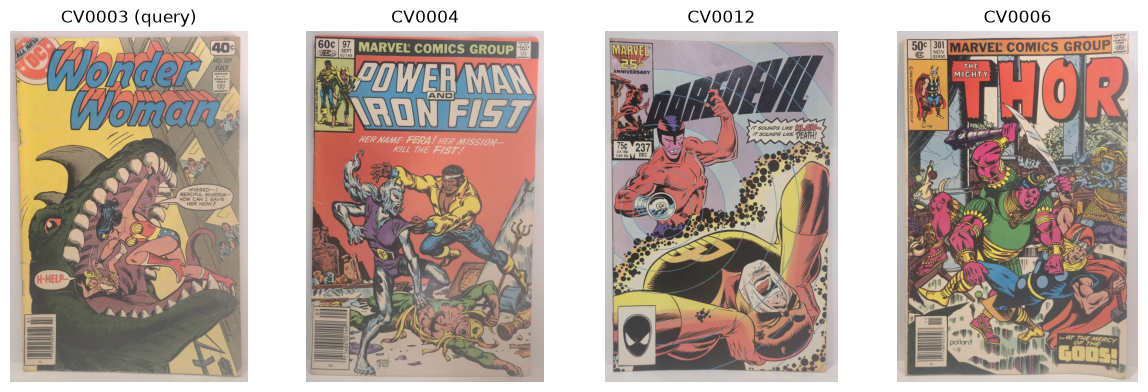

In [18]:
# Compare the query cover with its three closest color matches
import matplotlib.pyplot as plt

cover_ids = ["CV0003"] + closest_covers["comic_id"].tolist()
fig, axes = plt.subplots(1, 4, figsize=(12, 4))

for ax, comic_id in zip(axes, cover_ids):
    comic = train_data.loc[train_data["comic_id"] == comic_id].iloc[0]
    cover_path = Path(project_root) / comic["cover_image_path"]

    with Image.open(cover_path) as cover:
        ax.imshow(cover.convert("RGB"))

    ax.set_title(f"{comic_id} (query)" if comic_id == "CV0003" else comic_id)
    ax.axis("off")

fig.tight_layout()
plt.show()

### Interpreting the average RGB baseline

Among the training covers, CV0004 was closest to CV0003 by average RGB
distance (7.59), followed by CV0012 (9.42) and CV0006 (10.10).

CV0003 and CV0004 both use warm colors and blue title lettering, but
CV0003 has a mostly yellow background while CV0004 has a broad orange-red
background. Average RGB summarizes overall color and discards its location,
so a small distance can occur even when cover layouts differ.

In [19]:
# Compare average RGB in four regions of each cover
def quadrant_rgb(cover_path):
    with Image.open(cover_path) as cover:
        pixels = np.asarray(cover.convert("RGB"))

    height, width, _ = pixels.shape
    mid_row = height // 2
    mid_col = width // 2

    quadrants = {
        "Top left": pixels[:mid_row, :mid_col],
        "Top right": pixels[:mid_row, mid_col:],
        "Bottom left": pixels[mid_row:, :mid_col],
        "Bottom right": pixels[mid_row:, mid_col:],
    }

    return {
        name: region.mean(axis=(0, 1))
        for name, region in quadrants.items()
    }


for comic_id in ["CV0003", "CV0004"]:
    comic = train_data.loc[train_data["comic_id"] == comic_id].iloc[0]
    cover_path = Path(project_root) / comic["cover_image_path"]

    print(f"\n{comic_id} — average RGB by quadrant")
    for name, rgb in quadrant_rgb(cover_path).items():
        print(name, rgb.round(1))


CV0003 — average RGB by quadrant
Top left [176.1 154.  115.5]
Top right [162.3 147.5 135.9]
Bottom left [135.5 122.3 108.8]
Bottom right [155.5 137.5 121.1]

CV0004 — average RGB by quadrant
Top left [159.2 126.5 114.4]
Top right [181.2 147.2 138.3]
Bottom left [143.9 124.2 115.8]
Bottom right [158.5 140.3 127.2]


In [20]:
# Rank training covers by average RGB in corresponding quadrants
quadrant_features = {}

for _, comic in train_data.iterrows():
    cover_path = Path(project_root) / comic["cover_image_path"]
    regions = quadrant_rgb(cover_path)
    quadrant_features[comic["comic_id"]] = np.concatenate([
        regions["Top left"],
        regions["Top right"],
        regions["Bottom left"],
        regions["Bottom right"],
    ])

query_features = quadrant_features["CV0003"]
quadrant_matches = []

for comic_id, features in quadrant_features.items():
    if comic_id != "CV0003":
        distance = np.linalg.norm(features - query_features)
        quadrant_matches.append({
            "comic_id": comic_id,
            "quadrant_distance": distance,
        })

closest_quadrant_covers = pd.DataFrame(quadrant_matches).nsmallest(
    3, "quadrant_distance"
)
print(closest_quadrant_covers.round(2).to_string(index=False))


comic_id  quadrant_distance
  CV0004              39.80
  CV0012              43.93
  CV0014              45.04


### Comparing whole-cover and quadrant RGB

For training query CV0003, both methods ranked CV0004 first and CV0012
second. Quadrant RGB ranked CV0014 third, replacing CV0006.

Whole-cover RGB uses three channel averages. Quadrant RGB uses 12
averages and compares corresponding regions. We compared ranks because
the two distances are calculated in feature spaces of different sizes.
This training example shows a ranking change. Human relevance judgments
are needed to determine which ranking is more useful.

## Milestone 04 Summary — Preprocessing and Baselines

This milestone established reproducible text and image preprocessing for the
20-comic pilot and tested simple ways to rank comics by title and cover color.

### Dataset split

- Split the catalog by comic ID into 16 training comics and 4 holdout comics
  using random seed `42`. Verified that no comic IDs appeared in both sets.
- Fitted both TF-IDF vectorizers on training titles only. Applied the original
  vectorizer to the holdout titles to check vocabulary coverage and reserved
  the holdout comics for later evaluation.

### Title similarity baseline

- Used titles because the pilot catalog has no genre tags or descriptions.
- Compared titles with TF-IDF and cosine similarity. The default vocabulary
  contained 38 terms. Removing common English words reduced it to 32.
- Removing common words reduced positive-match coverage from **11 of 16**
  to **9 of 16** training comics. For CV0008 (*The Amazing Spider-Man Annual*),
  it removed two matches based on `the`, while the match based on `man` remained.
- Positive-match coverage measures how often the baseline finds shared terms.
  Human relevance judgments are needed to assess recommendation quality.

### Cover similarity baseline

- Extracted three mean RGB values for each whole cover and 12 mean RGB values
  across four quadrants. Used Euclidean distance to rank the training covers.
- For CV0003 (*Wonder Woman*), both methods ranked CV0004 first and CV0012
  second. Quadrant RGB moved CV0014 into third place, replacing CV0006.
- Quadrant averages retain coarse color location. The ranking change shows
  how that choice affects which covers are retrieved.

### Verification and next milestone

- A fresh kernel run reproduced the quadrant RGB ranking.
- All 30 existing repository tests passed.
- Milestone 05 will explore clustering with the 12 quadrant RGB features
  from the 16 training covers.